# 01 — Exploration des documents

Ce notebook analyse les deux textes du corpus avant toute construction du RAG :

- **RGPD** — Règlement (UE) 2016/679 ;
- **AI Act** — Règlement (UE) 2024/1689.

Objectifs :

1. vérifier que le texte des PDF s'extrait correctement ;
2. repérer et retirer les en-têtes et pieds de page répétés ;
3. découper les textes en articles et contrôler ce découpage ;
4. mesurer la longueur des articles pour choisir la taille des morceaux (*chunks*) à l'étape suivante.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from assistant_rag.config import DOCUMENTS
from assistant_rag.extraction import clean_pages, detect_boilerplate, extract_pages, split_articles

pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Extraction du texte brut

In [2]:
raw_pages = {key: extract_pages(source.path, key) for key, source in DOCUMENTS.items()}

pd.DataFrame(
    [
        {
            "document": DOCUMENTS[key].name,
            "pages": len(pages),
            "caractères": sum(len(page.text) for page in pages),
            "pages vides": sum(not page.text.strip() for page in pages),
        }
        for key, pages in raw_pages.items()
    ]
).set_index("document")

,pages,caractères,pages vides
document,,,
RGPD,88,473087,0
AI Act,144,780516,0


Une page vide signalerait un PDF scanné (texte sous forme d'image), qui demanderait une reconnaissance de caractères (OCR).

## 2. En-têtes et pieds de page

Les lignes qui se répètent en haut ou en bas de la plupart des pages (titre du Journal officiel, numérotation) n'apportent aucune information et perturberaient la recherche. Elles sont détectées en masquant les chiffres, pour que « L 119/12 » et « L 119/13 » soient reconnues comme la même ligne.

In [3]:
boilerplate = {key: detect_boilerplate(pages) for key, pages in raw_pages.items()}

for key, lines in boilerplate.items():
    print(f"{DOCUMENTS[key].name} :")
    for line in sorted(lines):
        print(f"  {line}")

RGPD :
  #.#.# FR Journal officiel de l'Union européenne L #/#
  L #/# FR Journal officiel de l'Union européenne #.#.#
AI Act :
  #/# ELI: http://data.europa.eu/eli/reg/#/#/oj
  ELI: http://data.europa.eu/eli/reg/#/#/oj #/#
  FR JO L du #.#.#


In [4]:
clean = {key: clean_pages(pages, boilerplate[key]) for key, pages in raw_pages.items()}

page_index = 9
print("--- Page brute ---")
print(raw_pages["rgpd"][page_index].text[:800])
print("\n--- Page nettoyée ---")
print(clean["rgpd"][page_index].text[:800])

--- Page brute ---
L 119/10          FR                         Journal officiel de l'Union européenne                                  4.5.2016


             responsable du traitement, quant à l'utilisation ultérieure desdites données; la nature des données à caractère
              personnel;  les conséquences pour  les personnes concernées du traitement ultérieur prévu;  et  l'existence de
              garanties appropriées à la fois dans le cadre du traitement initial et du traitement ultérieur prévu.


            Lorsque la personne concernée a donné son consentement ou que le traitement est fondé sur le droit de l'Union
           ou  le  droit  d'un  État membre  qui  constitue une mesure  nécessaire  et  proportionnée dans une  société
            démocratique pour  garantir, en  particulier, d'im

--- Page nettoyée ---
responsable du traitement, quant à l'utilisation ultérieure desdites données; la nature des données à caractère
personnel; les conséquences pour les personne

## 3. Longueur des pages

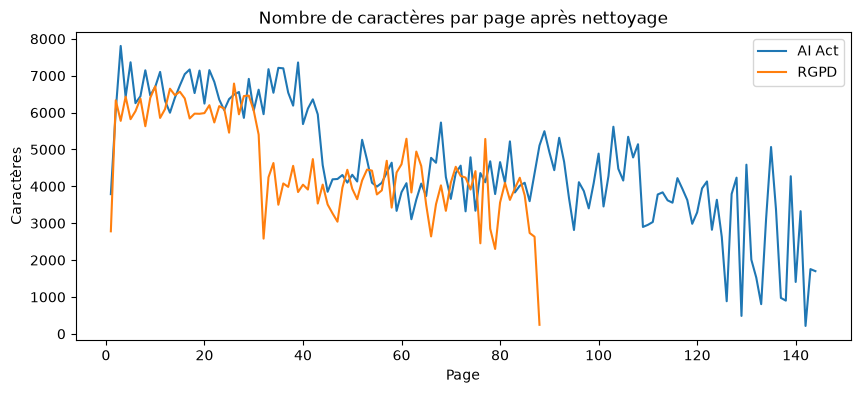

In [5]:
page_lengths = pd.DataFrame(
    [
        {"document": DOCUMENTS[key].name, "page": page.number, "caractères": len(page.text)}
        for key, pages in clean.items()
        for page in pages
    ]
)

fig, ax = plt.subplots()
for name, group in page_lengths.groupby("document"):
    ax.plot(group["page"], group["caractères"], label=name)
ax.set_xlabel("Page")
ax.set_ylabel("Caractères")
ax.set_title("Nombre de caractères par page après nettoyage")
ax.legend()
plt.show()

## 4. Découpage en articles

Chaque règlement est découpé en articles à partir des titres « Article N ». Un titre n'est retenu que s'il suit la numérotation attendue : les articles cités dans le corps du texte sont ainsi ignorés. Le nombre d'articles obtenu est comparé au nombre réel d'articles de chaque règlement.

In [6]:
articles = pd.DataFrame(
    [
        {
            "document": DOCUMENTS[article.document].name,
            "article": article.number,
            "titre": article.title,
            "chapitre": article.chapter,
            "page début": article.start_page,
            "page fin": article.end_page,
            "caractères": len(article.text),
            "mots": len(article.text.split()),
        }
        for pages in clean.values()
        for article in split_articles(pages)
    ]
)

summary = articles.groupby("document").agg(articles=("article", "count"), dernier=("article", "max"))
summary["attendus"] = summary.index.map({source.name: source.expected_articles for source in DOCUMENTS.values()})
summary

,articles,dernier,attendus
document,,,
AI Act,113,113,113
RGPD,99,99,99


In [7]:
articles.groupby("document").head(5)

,document,article,titre,chapitre,page début,page fin,caractères,mots
0,RGPD,1,Objet et objectifs,CHAPITRE I,32,32,613,97
1,RGPD,2,Champ d'application matériel,CHAPITRE I,32,32,1515,236
2,RGPD,3,Champ d'application territorial,CHAPITRE I,32,33,1074,173
3,RGPD,4,Définitions,CHAPITRE I,33,35,10138,1468
4,RGPD,5,Principes relatifs au traitement des données à caractère personnel,CHAPITRE II,35,36,2528,369
99,AI Act,1,Objet,CHAPITRE I,44,45,1290,201
100,AI Act,2,Champ d’application,CHAPITRE I,45,46,5378,853
101,AI Act,3,Définitions,CHAPITRE I,46,51,18920,2860
102,AI Act,4,Maîtrise de l’IA,CHAPITRE I,51,51,614,95
103,AI Act,5,Pratiques interdites en matière d’IA,CHAPITRE II,51,53,12204,1834


In [8]:
articles.sort_values("caractères").groupby("document").head(3)

,document,article,titre,chapitre,page début,page fin,caractères,mots
72,RGPD,73,Président,CHAPITRE VII,78,78,188,33
30,RGPD,31,Coopération avec l'autorité de contrôle,CHAPITRE IV,51,51,194,29
192,AI Act,94,Droits procéduraux des opérateurs économiques du modèle d’IA à usage général,CHAPITRE IX,113,113,205,29
196,AI Act,98,Comité,CHAPITRE XI,115,115,219,36
71,RGPD,72,Procédure,CHAPITRE VII,78,78,252,41
162,AI Act,64,Bureau de l’IA,CHAPITRE VII,95,95,275,42


Les articles les plus courts permettent de repérer un découpage raté (titre mal détecté, article vide).

## 5. Longueur des articles et taille des chunks

La taille d'un chunk s'exprime en *tokens*. Pour un texte en français, on utilise ici l'approximation d'un token pour 4 caractères ; le nombre exact dépendra du modèle d'embeddings choisi.

In [9]:
articles["tokens (approx.)"] = articles["caractères"] / 4

articles.groupby("document")["tokens (approx.)"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(0)

,count,mean,std,min,25%,50%,75%,90%,max
document,,,,,,,,,
AI Act,113.0,707.0,665.0,51.0,260.0,504.0,962.0,1350.0,4730.0
RGPD,99.0,533.0,483.0,47.0,158.0,379.0,758.0,1298.0,2534.0


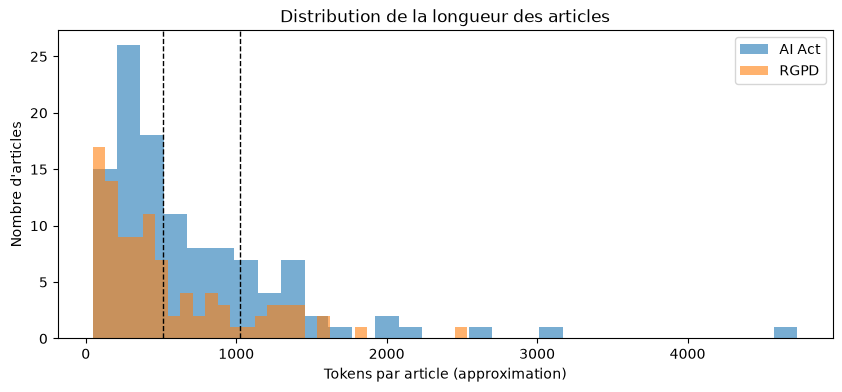

In [10]:
fig, ax = plt.subplots()
for name, group in articles.groupby("document"):
    ax.hist(group["tokens (approx.)"], bins=30, alpha=0.6, label=name)
for limit in (512, 1024):
    ax.axvline(limit, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Tokens par article (approximation)")
ax.set_ylabel("Nombre d'articles")
ax.set_title("Distribution de la longueur des articles")
ax.legend()
plt.show()

In [11]:
thresholds = [256, 512, 1024]
pd.DataFrame(
    {
        f"> {limit} tokens": articles.groupby("document")["tokens (approx.)"].apply(lambda s, n=limit: (s > n).mean())
        for limit in thresholds
    }
).map(lambda share: f"{share:.0%}")

,> 256 tokens,> 512 tokens,> 1024 tokens
document,,,
AI Act,77%,48%,22%
RGPD,68%,35%,16%


## 6. Conclusions

**Extraction.** Les 88 pages du RGPD et les 144 pages de l'AI Act contiennent du texte exploitable : aucune reconnaissance de caractères n'est nécessaire.

**Nettoyage.** Les en-têtes et pieds de page sont détectés automatiquement pour les deux mises en page du Journal officiel (format de 2016 pour le RGPD, format « JO L » avec lien ELI pour l'AI Act). Les mots coupés en fin de ligne sont recollés et les espaces multiples supprimés.

**Découpage.** Le découpage retrouve exactement les 99 articles du RGPD et les 113 articles de l'AI Act, avec leur titre, leur chapitre et leurs pages. Deux parties ne sont pas incluses dans les articles :

- les considérants, qui occupent les 31 premières pages du RGPD et les 43 premières de l'AI Act ;
- les annexes, situées après la formule finale « Fait à Bruxelles ».

**Longueur des articles.** La longueur médiane est d'environ 380 tokens pour le RGPD et 510 pour l'AI Act. Environ un tiers des articles du RGPD et la moitié de ceux de l'AI Act dépassent 512 tokens. Les articles de définitions sont les plus longs : environ 2 500 tokens pour l'article 4 du RGPD et 4 800 pour l'article 3 de l'AI Act.

**Choix pour le RAG.** L'article est l'unité de découpage naturelle : il correspond à la manière dont un juriste cite un texte. Les articles courts forment un seul chunk ; les articles longs sont redécoupés en morceaux d'environ 512 tokens avec chevauchement. Chaque chunk conserve le document, le numéro d'article, son titre et ses pages, ce qui permet de citer chaque source avec précision.